<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/video2_5_modelos_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5 modelos de visión gratis que puedes usar hoy en Colab
**Laboratorio de Códigos** · YOLO · SAM 2 · CLIP · Depth Anything · MediaPipe

Activa la GPU: `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`. Usa la misma imagen en los 5 para que el contraste se vea en el video.

In [ ]:
!pip install -q ultralytics transformers mediapipe

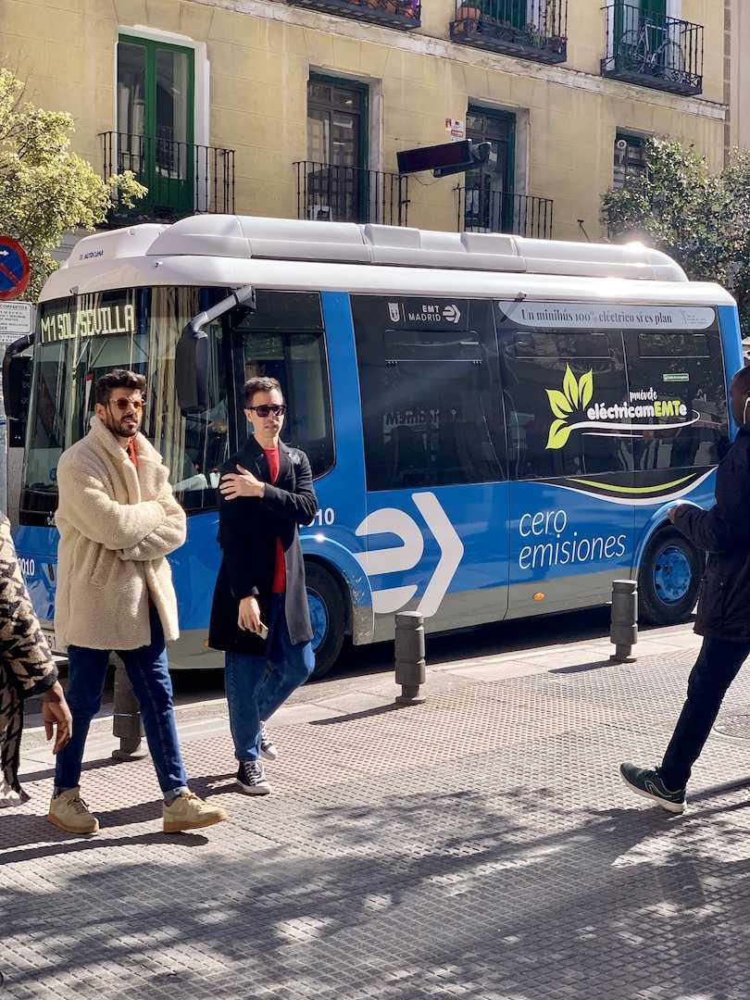

In [ ]:
import urllib.request
import cv2, numpy as np, matplotlib.pyplot as plt
from PIL import Image

IMG_URL = "https://ultralytics.com/images/bus.jpg"   # cámbiala por tu propia foto
IMG = "foto.jpg"
urllib.request.urlretrieve(IMG_URL, IMG)
original = Image.open(IMG).convert("RGB")
original

## 1. YOLO: detecta objetos

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Encontré: ['bus', 'person', 'person', 'person', 'person']


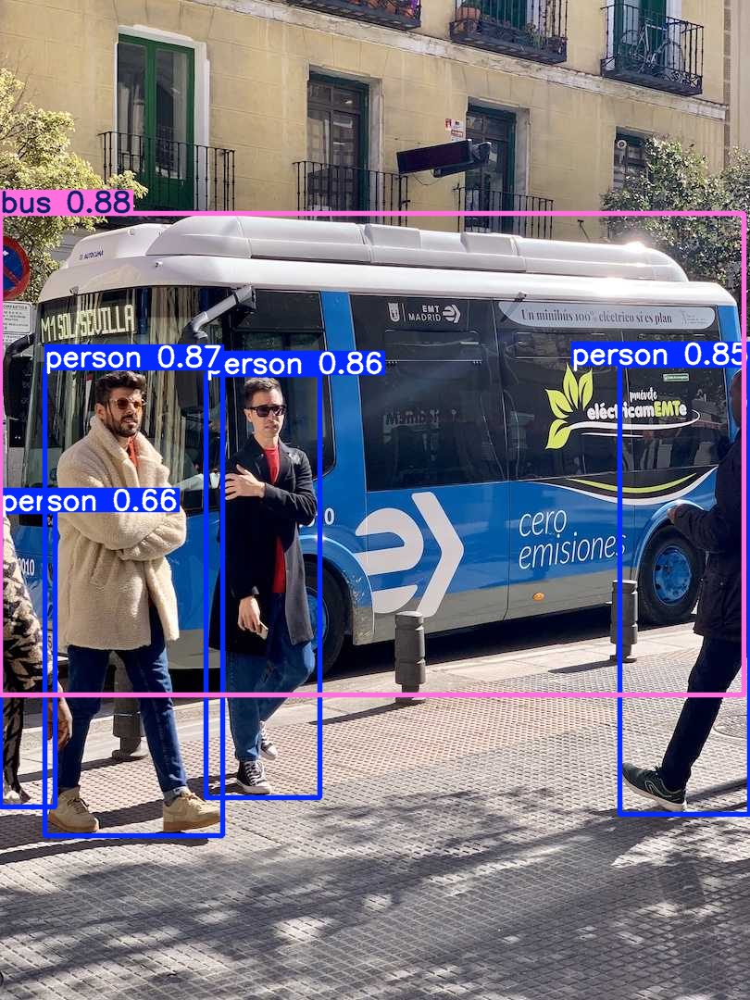

In [ ]:
from ultralytics import YOLO

yolo = YOLO("yolo26n.pt")          # o "yolo11n.pt"
r_yolo = yolo(IMG, verbose=False)[0]
img_yolo = r_yolo.plot()[:, :, ::-1]  # BGR -> RGB
print("Encontré:", [r_yolo.names[int(c)] for c in r_yolo.boxes.cls])
Image.fromarray(img_yolo)

## 2. SAM 2: recorta cada objeto al pixel (usando las cajas de YOLO)

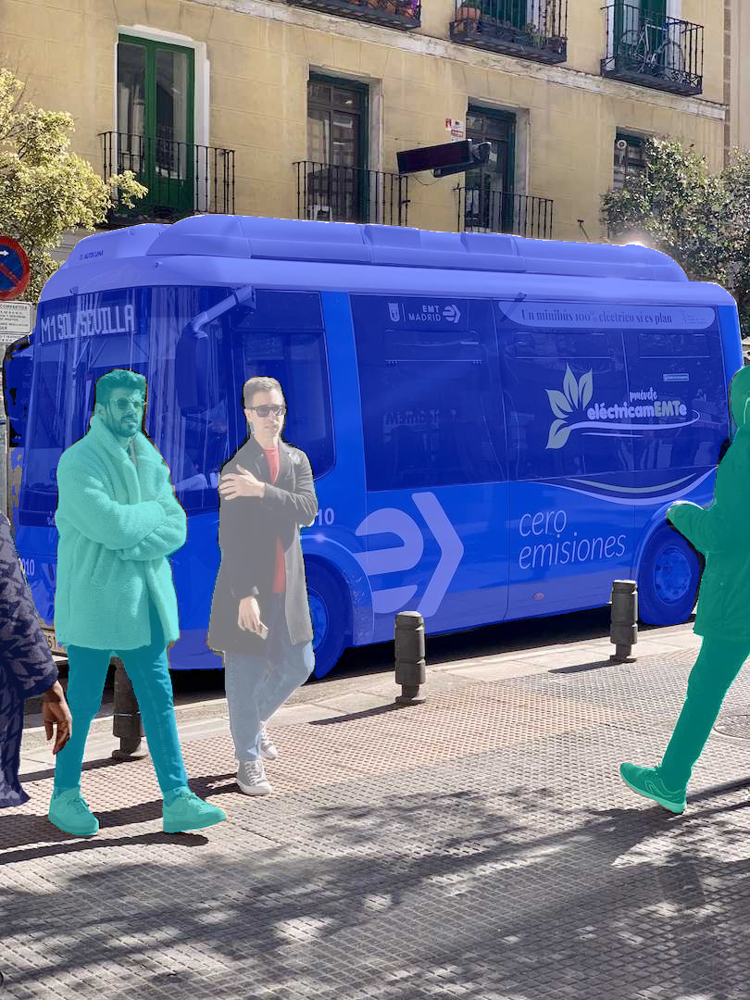

In [ ]:
from ultralytics import SAM

sam = SAM("sam2.1_b.pt")
cajas = r_yolo.boxes.xyxy.cpu().numpy().tolist()
r_sam = sam(IMG, bboxes=cajas, verbose=False)[0]
img_sam = r_sam.plot(boxes=False)[:, :, ::-1]
Image.fromarray(img_sam)

## 3. CLIP: entiende la escena sin entrenar (le das las opciones en texto)

In [ ]:
from transformers import pipeline

clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=0)
opciones = {
    "a city street": "calle de ciudad",
    "a beach": "playa",
    "a kitchen": "cocina",
    "a forest": "bosque",
    "an office": "oficina",
}
r_clip = clip(original, candidate_labels=list(opciones))
for r in r_clip:
    print(f"{opciones[r['label']]:<16} {r['score']*100:5.1f}%")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

calle de ciudad   99.1%
oficina            0.8%
cocina             0.1%
bosque             0.1%
playa              0.0%


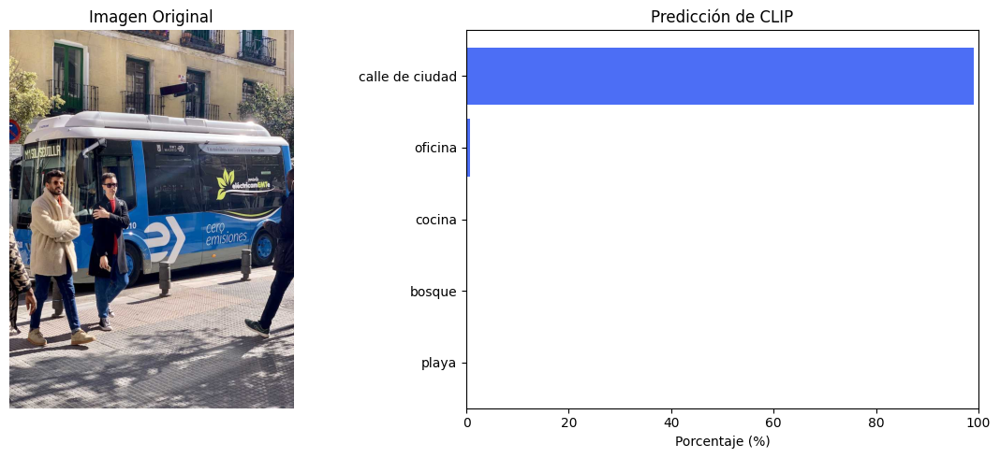

In [ ]:
import matplotlib.pyplot as plt

# Crear subplots para mostrar la imagen y los resultados lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Mostrar la foto original
ax1.imshow(original)
ax1.set_title("Imagen Original")
ax1.axis("off")

# Preparar los datos para la gráfica de barras de CLIP
etiquetas = [opciones[r['label']] for r in r_clip][::-1]
valores = [r['score'] * 100 for r in r_clip][::-1]

# Graficar los resultados
ax2.barh(etiquetas, valores, color="#4c6ef5")
ax2.set_xlim(0, 100)
ax2.set_xlabel("Porcentaje (%)")
ax2.set_title("Predicción de CLIP")

plt.tight_layout()
plt.show()

## 4. Depth Anything: calcula la profundidad con una sola foto

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

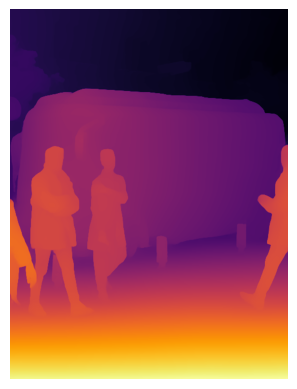

In [ ]:
prof = pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf", device=0)
mapa = np.array(prof(original)["depth"])
plt.imshow(mapa, cmap="inferno"); plt.axis("off"); plt.show()

## 5. MediaPipe: esqueleto del cuerpo (Pose Landmarker, Tasks API)

Personas con esqueleto: 1


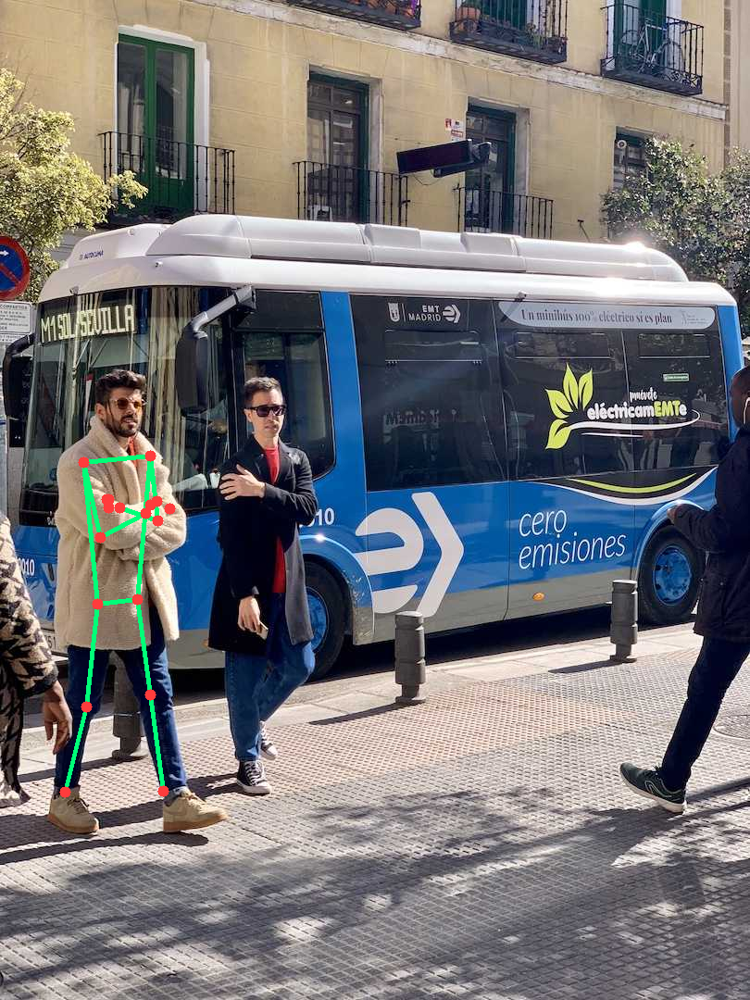

In [ ]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

urllib.request.urlretrieve(
    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/latest/pose_landmarker_lite.task",
    "pose_landmarker_lite.task")

opciones_pose = vision.PoseLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker_lite.task"),
    num_poses=5)
detector = vision.PoseLandmarker.create_from_options(opciones_pose)
r_pose = detector.detect(mp.Image.create_from_file(IMG))

CONEXIONES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),
              (23,24),(23,25),(25,27),(24,26),(26,28)]
img_pose = np.array(original).copy()
H, W = img_pose.shape[:2]
for persona in r_pose.pose_landmarks:
    pts = [(int(p.x * W), int(p.y * H)) for p in persona]
    for a, b in CONEXIONES:
        cv2.line(img_pose, pts[a], pts[b], (0, 255, 120), 4)
    for x, y in pts[11:29]:
        cv2.circle(img_pose, (x, y), 6, (255, 60, 60), -1)
print("Personas con esqueleto:", len(r_pose.pose_landmarks))
Image.fromarray(img_pose)

## Todo junto (el plano final del video)

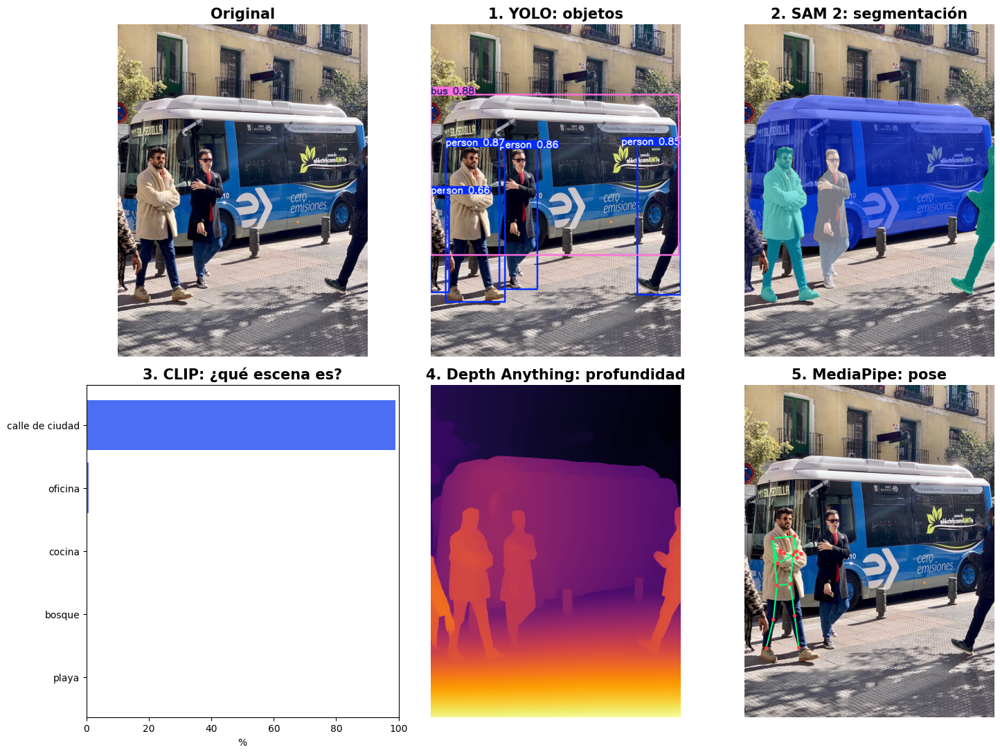

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 11))
paneles = [(np.array(original), "Original"), (img_yolo, "1. YOLO: objetos"),
           (img_sam, "2. SAM 2: segmentación"), (None, "3. CLIP: ¿qué escena es?"),
           (mapa, "4. Depth Anything: profundidad"), (img_pose, "5. MediaPipe: pose")]
for a, (img, titulo) in zip(ax.flat, paneles):
    a.set_title(titulo, fontsize=15, fontweight="bold")
    if titulo.startswith("3."):
        etiquetas = [opciones[r["label"]] for r in r_clip][::-1]
        valores = [r["score"] * 100 for r in r_clip][::-1]
        a.barh(etiquetas, valores, color="#4c6ef5"); a.set_xlim(0, 100); a.set_xlabel("%")
    else:
        a.imshow(img, cmap="inferno" if titulo.startswith("4.") else None); a.axis("off")
plt.tight_layout(); plt.savefig("5_modelos.png", dpi=150); plt.show()